# 05 逻辑回归实战与模型评估

第 05 个课程目录名为“逻辑回归”，教师笔记、代码和视频围绕同一章展开。前面的 04 篇已经讲过 sigmoid、极大似然和指标公式，本篇把知识串成一条可复用的实战流程：从电信客户流失数据开始，完成编码、训练、评估、交叉验证和阈值选择。

课程资料：`05-逻辑回归/02-笔记/逻辑回归.md`、`03-代码/04_电信客户流失案例分析.py`、`04-上课视频/第五章-逻辑回归-01~10`。本篇代码修正了原示例中用硬标签计算 AUC、全量 one-hot 和未分层切分等容易产生误解的地方。

资料：[机器学习课程网盘](https://pan.baidu.com/s/1NmWli9KoAeYtlpXTzhw-Jg?pwd=1234)，提取码 `1234`。网盘的第 04、05 目录共用一份逻辑回归教师笔记，所以本篇延续第 04 篇的主题。案例数据、参数和实际运行结果分开说明；新增验证练习明确标注为补充。

本篇延续已有笔记格式：全部使用 Markdown 单元，代码放在 Python 代码块中，复制到代码单元或脚本后运行。所有图片都保存在本 Notebook 的附件中，没有独立图片依赖。

## 1. 先明确任务：流失是正例

`Churn` 表示客户是否流失。本文约定：

- `Yes → 1`：流失，业务正例；
- `No → 0`：未流失，业务负例；
- `customerID` 只是标识符，不参与建模；
- 预测概率 `p` 表示“客户流失”的估计概率。

这个约定决定了 precision、recall、F1 和 `predict_proba()[:, 1]` 的含义。不要因为某个类别样本少，就自动把它当成正例。

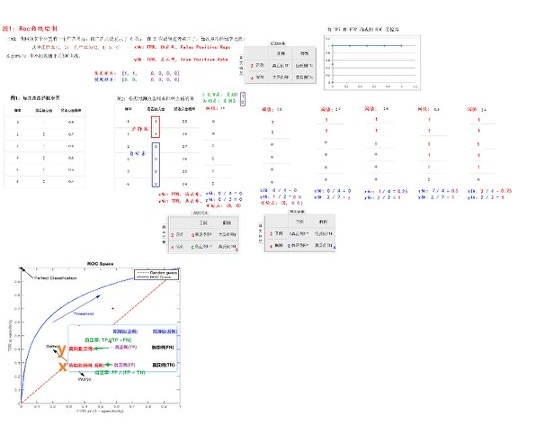

*这是本章随堂图的内容区域，裁去了大面积空白；原图文字较小，关键步骤已重写成下面的表格与清晰图表。*


### 1.1 先把第 04 篇的原理连起来

逻辑回归整体学习 $w,b$，先输出线性分数，再转成概率：

$$z=w^\mathsf{T}x+b,\qquad p=\sigma(z)=\frac{1}{1+e^{-z}}$$

训练时最小化二元交叉熵，而预测时才选阈值：

$$J=-\frac1m\sum_i\left[y_i\log p_i+(1-y_i)\log(1-p_i)\right],\qquad
\hat y=\mathbf 1[p\ge t]$$

三件事不要混在一起：损失决定参数怎么学，概率给出排序和置信信息，阈值决定最终标签。修改阈值不会重新训练模型，修改正则化或类别权重则会改变学习到的参数。

## 2. 一条完整的建模流水线

对一个新的二分类表格任务，可以按下面顺序检查：

1. 查看列名、数据类型、缺失值和目标比例；
2. 从原始目标列构造 `y`，删除目标和 ID，得到 `X`；
3. 切分训练集和测试集，二分类通常使用 `stratify=y`；
4. 在训练折内拟合缺失值填补、缩放和 one-hot 编码；
5. 训练逻辑回归，先用默认 L2 正则建立基线；
6. 用测试集概率计算 ROC-AUC，用标签计算混淆矩阵和分类报告；
7. 只有在验证集或 OOF 概率上选择阈值，最后再报告一次测试集成绩。

“预处理也属于模型”的意识很重要：如果先对全量数据编码、缩放或填补，再切分，测试集的信息就可能进入训练流程。

## 3. 读取数据并检查目标

课程的 `churn.csv` 约有 7043 行，标准 Telco 字段包含 `customerID`、`Contract`、`tenure`、`MonthlyCharges`、`TotalCharges` 和 `Churn`。实际文件以 `df.columns` 为准；教师课堂示例还使用了编码后的 `Contract_Month`、`internet_other`、`PaymentElectronic` 三个字段。

```python
import pandas as pd

df = pd.read_csv("data/churn.csv")
print(df.shape)
print(df.dtypes)
print(df["Churn"].value_counts(dropna=False))
print(df.isna().sum().sort_values(ascending=False).head(10))
```

`TotalCharges` 在部分 Telco 文件中含有空字符串。它应该转成数值，无法转换的值留给训练集内的填补器；不要把空字符串默默当成 0。

`tenure` 是使用电信服务的月数，`MonthlyCharges` 是每月费用，`TotalCharges` 是累计费用。课程说明中的“21 个字段”包含 ID 和目标，不是 21 个可直接投入模型的有效特征。

本轮已读取教师笔记、独立 `.py` 源代码、随堂图和视频文件目录。课程 CSV 在网盘可见，但没有取得文件内容，因此下文不会给出它的实跑成绩。需要实际成绩时，下载 CSV 后运行本篇流程。

## 4. 用 Pipeline 做安全预处理

数值列和类别列分别处理：数值列用中位数填补后标准化，类别列用众数填补后 one-hot。`handle_unknown="ignore"` 可以让测试集或未来数据出现新类别时不报错。

```python
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

def make_preprocessor(X):
    numeric = X.select_dtypes(include="number").columns.tolist()
    categorical = [c for c in X.columns if c not in numeric]
    return ColumnTransformer([
        ("num", Pipeline([
            ("impute", SimpleImputer(strategy="median")),
            ("scale", StandardScaler()),
        ]), numeric),
        ("cat", Pipeline([
            ("impute", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore")),
        ]), categorical),
    ])
```

### one-hot 是否需要删除一列

有截距的线性模型若保留全部虚拟变量，会存在冗余；逻辑回归配合 L2 正则通常仍能训练。为教学简化，原课删除一列性别和一列目标。**目标类别应构造为一维 `y`，而输入类别是否 `drop="first"` 是另一件事。** 两者不能混为一谈。

默认保留输入类别各列配合 L2 是本篇基线选择。删除某个输入列可能改变系数解释，`handle_unknown="ignore"` 遇到新类别时还会编码成全 0，这表示模型没有学过该类别，不表示它等同于所有已知类别。

### 4.1 目标列和 ID 的清理

```python
def split_churn(df, target="Churn", id_column="customerID"):
    data = df.copy()
    if not data.columns.is_unique:
        raise ValueError("存在重复列名，请先整理数据")
    if target not in data:
        raise KeyError(f"找不到目标列 {target!r}，实际列为 {list(data.columns)}")
    y = data.pop(target).map({"No": 0, "Yes": 1, 0: 0, 1: 1})
    if y.isna().any() or y.nunique() != 2:
        raise ValueError("Churn 必须只包含 No/Yes 两个类别")
    data = data.drop(columns=[id_column], errors="ignore")
    if "TotalCharges" in data:
        data["TotalCharges"] = pd.to_numeric(data["TotalCharges"], errors="coerce")
    # 防止已派生的目标 one-hot 列混入特征
    data = data.drop(columns=["flag", "Churn_Yes", "Churn_No"], errors="ignore")
    if data.shape[1] == 0:
        raise ValueError("没有可用特征")
    return data, y.astype(int)

X, y = split_churn(df)
print(X.shape, y.mean())
```

把目标列先从原表中 `pop` 出来，比 `get_dummies(df)` 后再猜哪一列是目标更稳妥。

## 5. 建立逻辑回归基线

```python
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=22, stratify=y
)
pipe = Pipeline([
    ("prep", make_preprocessor(X_train)),
    ("model", LogisticRegression(C=1.0, solver="lbfgs", max_iter=2000)),
])
pipe.fit(X_train, y_train)
prob = pipe.predict_proba(X_test)[:, 1]
pred = (prob >= 0.5).astype(int)
```

教师代码使用 `test_size=0.2, random_state=22`；另一个讲义片段使用了 `random_state=21`。随机种子只影响本次切分，不能理解为模型性能参数。这里加上分层切分，使训练集和测试集的流失比例更接近。

本节是课堂基线；如果继续做 8、9 节的调参和阈值优化，就把测试集留到所有选择结束后再查看。完整的训练/验证/测试示例在第 12 节。

建议记录一个简单对照：始终预测“未流失”的模型。若模型 accuracy 只是略高于该基线而 recall 仍接近 0，通常无法支持流失挽留任务。

## 6. 分类指标：同一组预测回答不同问题

设流失为正例：

| 指标 | 公式 | 业务问题 |
|---|---|---|
| Accuracy | $(TP+TN)/N$ | 总体预测有多少正确？ |
| Precision | $TP/(TP+FP)$ | 被标记为可能流失的人，有多少真的流失？ |
| Recall | $TP/(TP+FN)$ | 所有真实流失客户，有多少被发现？ |
| F1 | $2PR/(P+R)$ | precision 和 recall 的平衡如何？ |

流失客户通常是少数类。若全预测为“未流失”，accuracy 可能看起来不错，但流失 recall 会是 0。评价前先决定漏掉一个流失客户和误联系一个正常客户哪个代价更高。

### 6.1 分母必须记对

| 判断 | 对照 |
|---|---|
| Precision 的分母 | 所有**预测为流失**的客户，即 TP+FP |
| Recall 的分母 | 所有**实际流失**的客户，即 TP+FN |
| Specificity（特异度） | TN/(TN+FP)，识别负例的比例 |
| FPR | FP/(FP+TN)=1−specificity |

`zero_division=0` 是分母为 0 时的软件约定，并不是该分式在数学上有定义。F1 只综合正例 precision 与 recall，没有直接计入 TN，也不表示运营成本最小。

### 6.2 混淆矩阵与分类报告

```python
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)

tn, fp, fn, tp = confusion_matrix(y_test, pred, labels=[0, 1]).ravel()
print({"TN": tn, "FP": fp, "FN": fn, "TP": tp})
print("accuracy:", accuracy_score(y_test, pred))
print("precision:", precision_score(y_test, pred, zero_division=0))
print("recall:", recall_score(y_test, pred, zero_division=0))
print("f1:", f1_score(y_test, pred, zero_division=0))
print(classification_report(
    y_test, pred, labels=[0, 1], target_names=["未流失", "流失"], zero_division=0
))
```

矩阵行是真实标签、列是预测标签，固定 `labels=[0, 1]` 后才可安全地按 `TN, FP, FN, TP` 解包。报告中的 `macro avg` 对类别等权，`weighted avg` 按 support 加权；类别不平衡时应同时看流失这一行。

### 6.3 同样的准确率，为什么结论不同

课堂有 6 个恶性和 4 个良性样本，以恶性为正例。A 预测 TP=3、FN=3、FP=0、TN=4；B 预测 TP=6、FN=0、FP=3、TN=1。

| 模型 | Accuracy | Precision | Recall | F1 | 错误侧重点 |
|---|---:|---:|---:|---:|---|
| A | 0.70 | 1.000 | 0.500 | 0.667 | 漏掉一半正例 |
| B | 0.70 | 0.667 | 1.000 | 0.800 | 增加三个误报 |

```python
import numpy as np
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

toy_y = np.array([1]*6+[0]*4)
toy_a = np.array([1,1,1,0,0,0,0,0,0,0])
toy_b = np.array([1,1,1,1,1,1,1,1,1,0])
for name, prediction in [("A",toy_a),("B",toy_b)]:
    print(name, confusion_matrix(toy_y,prediction,labels=[0,1]))
    print(accuracy_score(toy_y,prediction),
          precision_score(toy_y,prediction),
          recall_score(toy_y,prediction),
          f1_score(toy_y,prediction))
```

将这个例子迁移到流失任务：A 的“待联系名单”更纯，B 找到更多真实流失者。任务收益和联系成本决定如何取舍。

## 7. AUC 必须使用概率或分数

ROC 曲线改变阈值，记录 $FPR=FP/(FP+TN)$ 和 $TPR=TP/(TP+FN)$。AUC 衡量排序能力：随机抽一个流失客户和一个未流失客户，模型把前者分数排在后者前面的概率。

```python
from sklearn.metrics import roc_curve, roc_auc_score

fpr, tpr, thresholds = roc_curve(y_test, prob, drop_intermediate=False)
auc = roc_auc_score(y_test, prob)
print("AUC:", auc)
print("first ROC rows:")
print(list(zip(thresholds[:5], fpr[:5], tpr[:5])))
```

原课代码写成 `roc_auc_score(y_test, y_predict)`，其中 `y_predict` 是 0/1 硬标签。这段代码虽然有时能返回一个数，但只保留了一个阈值点，失去了排序信息。应使用 `predict_proba()[:, 1]` 或 `decision_function()`。

### 7.1 先定位概率列

如果用原始标签 2/4 或字符串训练，不能不检查 `classes_` 就取第二列。本篇统一重编码为 0/1，是为了让 1 的业务含义清楚：

```python
import numpy as np

# 依赖已经训练的 pipe 和 X_test
positive_label = 1
positive_column = np.flatnonzero(pipe.classes_ == positive_label)[0]
positive_probability = pipe.predict_proba(X_test)[:,positive_column]
```

ROC 的四个角可以这样记：`(0,0)` 全预测负，`(1,1)` 全预测正，`(0,1)` 全预测正确，`(1,0)` 全预测反。连续阈值还包括从全负开始的起点，sklearn 通常用 `np.inf` 表示第一个阈值。

### 7.2 ROC 阈值的直观过程

课程六个广告样本的真实标签为 `[1,0,1,0,0,0]`，分数为 `[0.9,0.7,0.8,0.6,0.5,0.4]`。按分数从高到低加入样本，ROC 点为：

| 动作 | FPR | TPR |
|---|---:|---:|
| 尚未选正例 | 0 | 0 |
| 加入 0.9 的正例 | 0 | 0.5 |
| 加入 0.8 的正例 | 0 | 1 |
| 加入 0.7 的负例 | 0.25 | 1 |
| 加入 0.6 的负例 | 0.50 | 1 |
| 加入 0.5 的负例 | 0.75 | 1 |
| 加入 0.4 的负例 | 1 | 1 |

因此 AUC=1，表示这组样本中正例排序完全在负例之前；它不等于阈值 0.5 下的 accuracy，也不保证未来数据仍为 1。

```python
import numpy as np
from sklearn.metrics import roc_curve, roc_auc_score, accuracy_score

ad_y = np.array([1,0,1,0,0,0])
ad_prob = np.array([0.9,0.7,0.8,0.6,0.5,0.4])
ad_fpr, ad_tpr, ad_threshold = roc_curve(ad_y,ad_prob,drop_intermediate=False)
print(np.c_[ad_threshold,ad_fpr,ad_tpr])
print("ROC-AUC:",roc_auc_score(ad_y,ad_prob))
print("accuracy at 0.5:",accuracy_score(ad_y,(ad_prob>=0.5).astype(int)))
```

得到 AUC=1、accuracy=0.5。说明模型虽然排序正确，但所选阈值仍可能产生很多误报。硬标签也可以传给 AUC API，但不应把那个数当作完整概率排序的评估。

### 7.3 不平衡数据补看 PR 曲线与 AP

PR 曲线的横轴是 recall、纵轴是 precision。正例很少时，它更直接反映“在多找正例的同时，名单中混进了多少负例”。

```python
from sklearn.metrics import average_precision_score, precision_recall_curve

# 依赖课程基线的 y_test、prob
pr_precision, pr_recall, pr_thresholds = precision_recall_curve(y_test,prob)
print("Average precision:",average_precision_score(y_test,prob))
print("正例比例:",y_test.mean())
```

AP（average precision）按 recall 的增量对 precision 加权，是常用的 PR 曲线总结指标；它与对 PR 曲线作普通梯形积分的结果不一定相同，报告时应写清名称。PR 曲线的 precision/recall 数组比 thresholds 多一个终点，不要不检查长度就一起拼表。不同正例比例的数据集上，AP 不适合直接横向比较。

## 8. 交叉验证与正则化

基线完成后，再在训练集内部调参。`C` 是正则化强度的倒数，越小正则越强；`class_weight="balanced"` 会提高少数类样本在训练损失中的权重。

```python
from sklearn.model_selection import StratifiedKFold, GridSearchCV

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=21)
search = GridSearchCV(
    pipe,
    {
        "model__C": [0.01, 0.1, 1, 10, 100],
        "model__class_weight": [None, "balanced"],
    },
    scoring="roc_auc", cv=cv, n_jobs=-1,
)
search.fit(X_train, y_train)
print(search.best_params_)
print(search.best_score_)
```

因为 `pipe` 包含预处理器，网格搜索会在每个训练折内重新拟合填补、缩放和编码。最后才用 `search.best_estimator_` 对测试集作一次评估，不要根据测试集结果反复改网格。

### 8.1 如何选择评分标准

| 任务目标 | 可用的验证评分 | 还需要考虑 |
|---|---|---|
| 输出风险排序 | `roc_auc` | 概率是否校准、如何行动 |
| 正例检索且很不平衡 | `average_precision` | 联系名单大小、正例比例 |
| 少漏掉流失客户 | `recall` | 误报和人力成本 |
| 同时兼顾查准与查全 | `f1` | 隐含的默认阈值、业务成本 |

1.8 起 sklearn 弃用 `penalty`，新版用 `l1_ratio` 指定 L1/L2 的组合。本文用默认 L2 和 `C`，便于跨版本练习；旧课程出现的 `penalty='l2'` 是旧 API 写法。L1/Elastic Net 的 solver 兼容性需单独核对，不能只改参数名称。

## 9. 阈值选择：让模型服务于业务

模型输出分数，阈值决定行动。默认 0.5 只是一个起点：如果运营团队只能联系少量客户，可以提高阈值；如果漏掉流失客户代价很高，可以降低阈值。阈值必须在验证集或 OOF 概率上选择，不能在测试集上试出最优后再宣称测试成绩。

```python
import numpy as np
from sklearn.metrics import precision_score, recall_score

def choose_threshold(y_true, score, min_recall=0.8):
    truth = np.asarray(y_true)
    score = np.asarray(score, dtype=float)
    if truth.ndim != 1 or score.shape != truth.shape:
        raise ValueError('标签与概率必须是一维且长度相同')
    if set(np.unique(truth)) != {0, 1}:
        raise ValueError('验证数据必须同时包含 0 和 1')
    if not np.isfinite(score).all() or not ((score >= 0) & (score <= 1)).all():
        raise ValueError('输入必须是有限的 0~1 概率')
    if not 0 <= min_recall <= 1:
        raise ValueError('min_recall 必须在 0~1 内')
    rows = []
    for threshold in np.unique(np.r_[0.0, score, 1.0]):
        pred = (score >= threshold).astype(int)
        p = precision_score(truth, pred, zero_division=0)
        r = recall_score(truth, pred, zero_division=0)
        if r >= min_recall:
            rows.append((p, r, float(threshold)))
    if not rows:
        raise ValueError('没有阈值达到召回目标')
    return max(rows)

# validation_score 应来自独立验证集或训练集的 OOF 概率
# precision, recall, threshold = choose_threshold(y_valid, validation_score)
```

固定模型后降低阈值，TP 和 FP 通常都会增加，recall 不会下降，但 precision 不保证单调。把阈值、联系人数上限、优惠成本和挽回收益一起记录，才是完整的模型评估。

如果多个阈值拥有相同 precision，本函数优先取 recall 更大的候选，再取阈值更高者。它要求验证数据同时包含 0 和 1，输入是概率。阈值 0 会把所有样本判为正例，保证有召回率为 1 的候选，但业务上往往无法承担这样的联系名单。

对概率已经校准、误报成本为 $c_{FP}$、漏报成本为 $c_{FN}$ 的简单问题，理论阈值是 $c_{FP}/(c_{FP}+c_{FN})$。这依赖成本、概率和部署分布都适用，不能把它当作所有模型的固定答案。

## 10. 课程示例的差异与修正

教师代码使用 `pd.get_dummies()` 后删除 `gender_Male`、`Churn_No`，将 `Churn_Yes` 改名为 `flag`，再选取三个字段训练；这是便于课堂演示的最短路径。本篇保留它的学习顺序，但给出以下修正：

1. 先从原始 `Churn` 分离标签，避免目标 one-hot 列混入 `X`；
2. one-hot、填补、缩放放进 Pipeline，防止测试信息泄漏；
3. 切分时使用 `stratify=y`；
4. `roc_auc_score` 使用连续概率，不使用 `y_predict`；
5. `classification_report` 显式指定标签和类别名称；
6. 不把合同类型与流失的相关性直接写成因果关系。

教师代码中的 `Contract_Month`、`PaymentElectronic`、`internet_other` 是编码后的课程字段。不同版本或不同来源的 Telco CSV 可能没有这些列，先打印 `data.columns` 再选择特征。

原源代码的注释还把 macro average 描述成“所有分类器平均”或“所有特征权重一样”。分类报告平均的是**各类别的指标**；macro 不按类别数量加权，weighted 按各类真实 support 加权，二者都不是在给输入特征分配权重。

## 11. 一份可复用的训练函数

下面函数不依赖固定的三列课程字段，适合先做基线。它只返回模型和测试切分，便于后续在验证阶段选择阈值。

```python
def fit_churn_baseline(df):
    X, y = split_churn(df)
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.20, random_state=22, stratify=y
    )
    pipe = Pipeline([
        ("prep", make_preprocessor(X_train)),
        ("model", LogisticRegression(C=1.0, solver="lbfgs", max_iter=2000)),
    ])
    pipe.fit(X_train, y_train)
    return pipe, {
        "X_train": X_train, "X_test": X_test,
        "y_train": y_train, "y_test": y_test,
    }

# model, splits = fit_churn_baseline(pd.read_csv("data/churn.csv"))
# score = model.predict_proba(splits["X_test"])[:, 1]
# print(roc_auc_score(splits["y_test"], score))
```

如果目标类别只有一个、`TotalCharges` 整列无法转换，或特征列全为空，函数应在数据检查阶段报错，而不是继续输出看似正常的指标。

此函数按“调用 4 节和 5 节的定义后再调用”的顺序使用。`make_preprocessor` 从输入列类型建立规则，在 fit 时学习填补值和编码类别。全为空的列、混入字符串的数值列和高度不平衡的少量样本，应先检查后处理；不要把 Pipeline 当成自动修复任意数据质量问题的工具。

## 12. 补充练习：把训练、验证、测试严格分开

sklearn 自带的 `load_breast_cancer` 无需网络：569 行、30 个特征；原始标签 `0=恶性、1=良性`。它与课程的 Wisconsin 原始 CSV（699 行、9 个特征，类别 2/4）不同。本节把恶性重编码为 1，练习整个分类流程，不混用两套样本统计。

本例的顺序是：先留 20% 测试集；剩余数据分出 25% 验证集，即约 60% 训练、20% 验证、20% 测试。参数搜索只用训练集，阈值只用验证集，测试集只做最终报告。验证集选完阈值后保留原模型，不再用训练+验证重新拟合，否则概率分布变化可能令旧阈值失效。

### 12.1 完整代码

先运行第 9 节的 `choose_threshold` 函数，再运行本段。代码使用独立的 `c_` 变量，避免与课程流失案例混淆。

```python
import numpy as np
from sklearn.datasets import load_breast_cancer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, roc_auc_score, average_precision_score, log_loss

c_data = load_breast_cancer(as_frame=True)
c_X = c_data.data
c_y = (c_data.target == 0).astype(int)
c_X_dev, c_X_test, c_y_dev, c_y_test = train_test_split(
    c_X, c_y, test_size=0.20, random_state=22, stratify=c_y
)
c_X_fit, c_X_valid, c_y_fit, c_y_valid = train_test_split(
    c_X_dev, c_y_dev, test_size=0.25, random_state=21, stratify=c_y_dev
)
c_pipe = Pipeline([
    ('scale', StandardScaler()),
    ('model', LogisticRegression(solver='lbfgs', max_iter=2000)),
])
c_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=21)
c_search = GridSearchCV(
    c_pipe,
    {'model__C':[0.01, 0.1, 1, 10],
     'model__class_weight':[None, 'balanced']},
    scoring='roc_auc', cv=c_cv, n_jobs=1,
)
c_search.fit(c_X_fit, c_y_fit)
c_valid_prob = c_search.predict_proba(c_X_valid)[:, 1]
c_precision, c_recall, c_threshold = choose_threshold(
    c_y_valid, c_valid_prob, min_recall=0.95
)
# 最后评估时固定训练模型和验证集选出的阈值。
c_test_prob = c_search.predict_proba(c_X_test)[:, 1]
c_test_pred = (c_test_prob >= c_threshold).astype(int)
c_results = {
    'accuracy':accuracy_score(c_y_test, c_test_pred),
    'precision':precision_score(c_y_test, c_test_pred),
    'recall':recall_score(c_y_test, c_test_pred),
    'f1':f1_score(c_y_test, c_test_pred),
    'roc_auc':roc_auc_score(c_y_test, c_test_prob),
    'average_precision':average_precision_score(c_y_test, c_test_prob),
    'log_loss':log_loss(c_y_test, c_test_prob),
}
c_matrix = confusion_matrix(c_y_test,c_test_pred,labels=[0,1])
print("样本数:",len(c_y_fit),len(c_y_valid),len(c_y_test))
print("参数:",c_search.best_params_)
print("验证阈值:",c_threshold,c_precision,c_recall)
print("测试结果:",c_results)
print(c_matrix)
```

### 12.2 本轮实跑结果

运行环境：scikit-learn 1.9.1、NumPy 2.5.4、pandas 3.0.6。训练集 341 行、验证集 114 行、测试集 114 行。

训练集五折 CV 选出 `C=0.1`、`class_weight=None`，平均 ROC-AUC 为 0.991249。验证集要求恶性 recall 至少 0.95，选出阈值 0.615477，验证 precision=1.000000、recall=0.953488。

| 最终测试指标 | 结果 |
|---|---:|
| Accuracy | 0.964912 |
| 恶性 Precision | 1.000000 |
| 恶性 Recall | 0.904762 |
| 恶性 F1 | 0.950000 |
| ROC-AUC | 0.997685 |
| AP | 0.996319 |
| Log loss | 0.100434 |

混淆矩阵按 `[0,1]` 排列，TN=72、FP=0、FN=4、TP=38。这些数字只属于上述内置数据和固定切分，不能写成课程 CSV 的成绩；本例用于算法学习。

验证集达到 95% recall，不代表未来样本或测试集也必须达到 95%。阈值选择和泛化成绩需要分别报告，不能把验证目标当成部署保证。

Log loss 评价概率本身对真实标签的拟合程度，越小越好；它会严厉惩罚非常自信的错误预测。ROC-AUC 高说明排序较好，不等于输出的每个概率都准确，必要时应另用校准曲线检验。


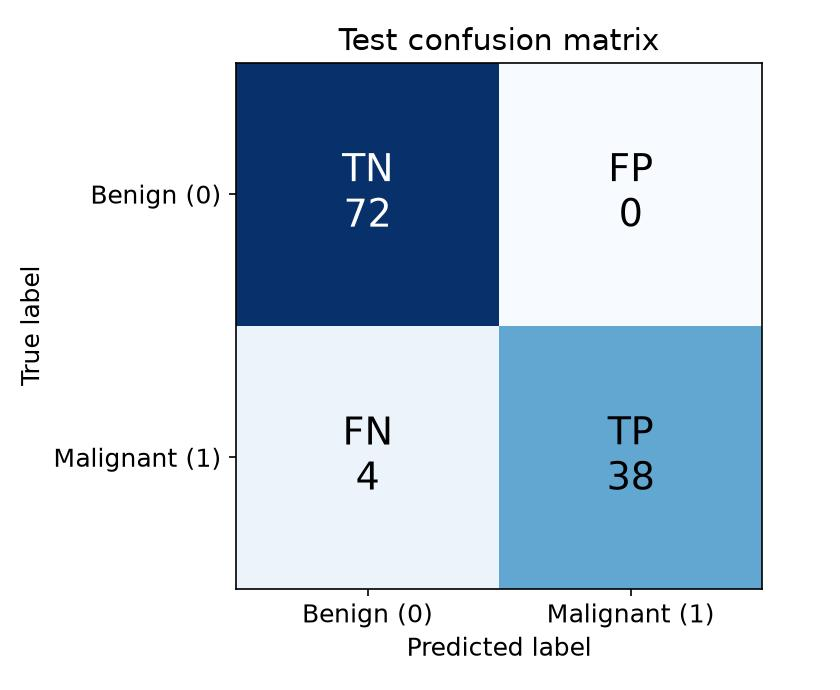

*行是真实标签，列是预测标签；1 表示恶性正例。*


### 12.3 ROC、PR 与阈值图如何一起看

ROC/AP 衡量整个分数排序，混淆矩阵对应一个已固定的阈值。验证阈值图可以帮助解释为什么选择某个阈值：recall 的目标是约束，precision 是符合约束后的选择标准。

下图横纵轴使用英文以保证不同环境字体可显示：FPR=假正例率，TPR=召回率；PR 横轴 Recall、纵轴 Precision。PR 灰色水平线是测试集正例比例，只作为排序基线参考。

阈值图按验证集的实际分数画成阶梯；橙色标记对应选中阈值的 recall，概率恰好等于阈值时按本文约定计为正例。


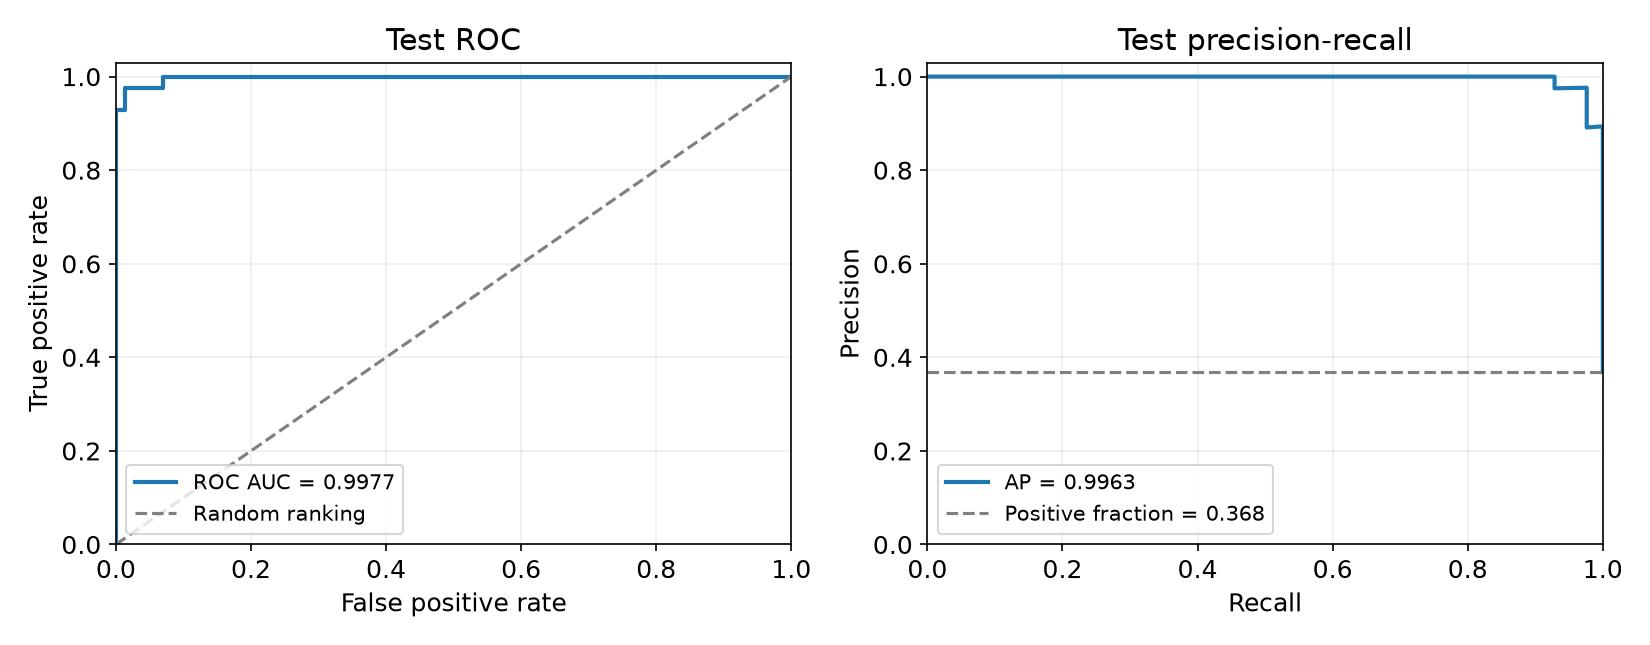

*由本篇固定切分实跑概率生成，图中标注 ROC-AUC 和 AP。*


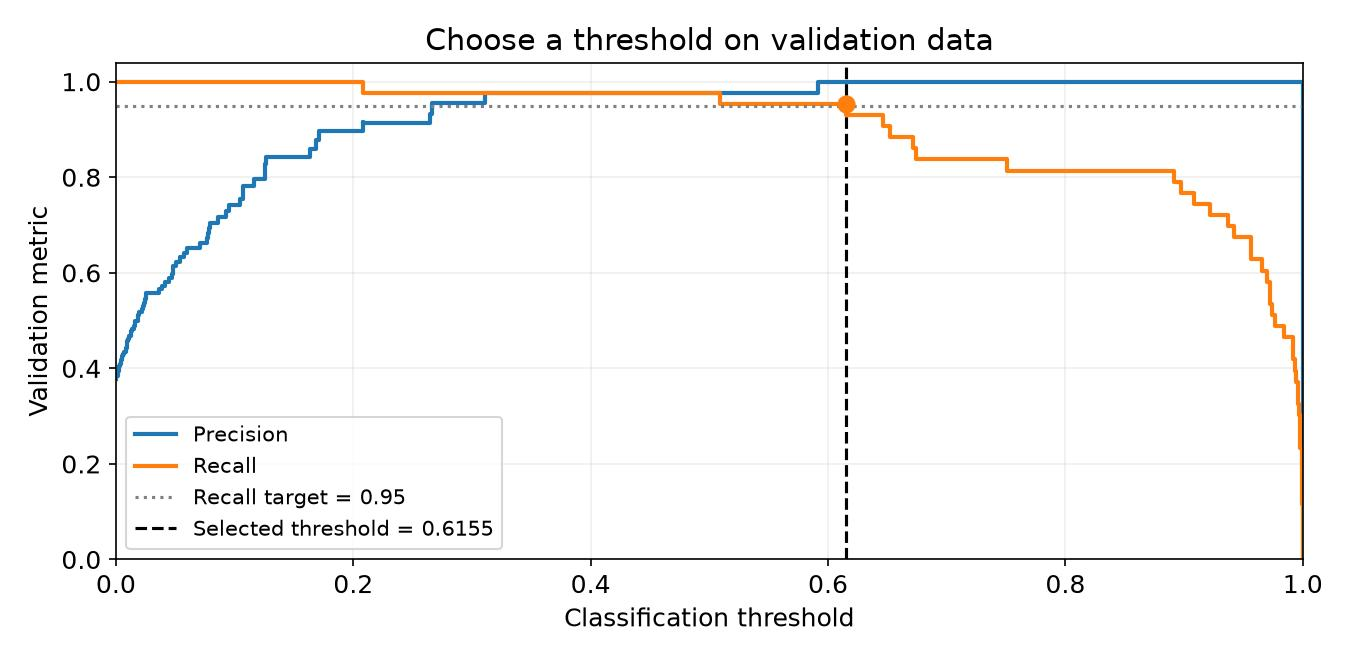

*只用验证集选阈值；虚线为最终阈值，点线为 0.95 的召回目标。*


### 12.4 自己绘制曲线

```python
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, precision_recall_curve

fig, axes = plt.subplots(1,2,figsize=(10,4))
c_fpr,c_tpr,_ = roc_curve(c_y_test,c_test_prob)
axes[0].plot(c_fpr,c_tpr,label=f"AUC={c_results['roc_auc']:.4f}")
axes[0].plot([0,1],[0,1],"--",color="gray")
axes[0].set(xlabel="False positive rate",ylabel="True positive rate",title="Test ROC")
c_pr_precision,c_pr_recall,_ = precision_recall_curve(c_y_test,c_test_prob)
axes[1].plot(c_pr_recall,c_pr_precision,label=f"AP={c_results['average_precision']:.4f}")
axes[1].axhline(c_y_test.mean(),linestyle="--",color="gray")
axes[1].set(xlabel="Recall",ylabel="Precision",title="Test PR")
for ax in axes:
    ax.legend()
    ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()
```

`plt.show()` 显示图而不写独立图片文件；本笔记中的已生成曲线则通过附件嵌入。

## 13. 评估结果怎样写成业务结论

不要只写“模型准确率很高”。一份可复核的记录应包含：目标和正例定义、数据来源与时间范围、训练/验证/测试数量、训练参数、选阈值的规则、最终阈值、混淆矩阵、正例指标及概率排序指标。

针对流失任务，可以写成：“在该时间段的留出数据上，选定阈值发现了多少真实流失者，同时误报多少未流失者；预计联系多少人。”模型给出的预测关联不能证明导致流失的原因，也不能直接证明优惠会挽回用户。

如果同一客户有多条记录，应按客户分组切分；预测未来流失时应按时间设计观察窗口、预测窗口并切分，排除流失之后才出现的字段。本文的随机分层切分适合教学用的一人一行静态表，不能照搬到所有业务数据。

## 14. 常见错误对照

| 容易出错的写法 | 改法和原因 |
|---|---|
| 少数类默认是正例 | 由业务指定正例并明确编码 |
| 用 `predict` 算 AUC | 使用业务正例的概率或连续分数 |
| AUC=1 就认为未来完美 | 只说明该评估集完全排序正确 |
| `C` 越大正则越强 | `C` 越小正则越强 |
| 测试集上反复试阈值 | 在验证集或 OOF 上选择，再评估测试集 |
| one-hot 后把 `Churn_Yes` 放入 X | 先分离 y，排除目标派生列 |
| 全量标准化后做 CV | 在 Pipeline 内每折重新拟合 |
| 只看 weighted F1 | 查看正例行、macro 及混淆矩阵 |
| 业务结论直接写“某字段导致流失” | 区分预测关联与因果关系 |

测试集中只有一个类别时，ROC-AUC 无定义，应重新审查切分或报告该限制。出现收敛警告时，先检查尺度和数据质量，再考虑增加 `max_iter`，不要直接忽略警告。

## 15. 练习和检查清单

1. 用课程 `churn.csv` 打印流失比例，并比较 `stratify=y` 与不分层切分的差别；
2. 分别用 `C=0.01、1、100` 训练，观察 AUC、流失 recall 和系数变化；
3. 比较 `class_weight=None` 与 `balanced`，说明为什么选择某个评分指标；
4. 在验证集上选择流失 recall 不低于 80% 的阈值，再只在测试集报告一次；
5. 把 `roc_auc_score(y_test, pred)` 和 `roc_auc_score(y_test, prob)` 的结果并列，解释为什么前者不能代表完整 ROC；
6. 检查是否有 ID、目标派生列或流失发生之后才产生的字段混入特征。

完成本篇后，应能从原始 CSV 走到一份可解释的二分类评估报告，并能说明每一个指标、阈值和数据处理步骤服务于什么业务决定。

完成标准：代码能从原始数据走到最终报告；能指出训练阶段和评估阶段各自使用了哪些数据；能够给出清晰的 TP/FP/FN/TN 数量和阈值依据。